<a href="https://colab.research.google.com/github/aishwaryaaramanathan/DL_Lab_241501011/blob/main/dl_exp_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1, Loss: 0.0882
Epoch 2, Loss: 0.0409
Epoch 3, Loss: 0.0322
Epoch 4, Loss: 0.0275
Epoch 5, Loss: 0.0241
Epoch 6, Loss: 0.0217
Epoch 7, Loss: 0.0199
Epoch 8, Loss: 0.0183
Epoch 9, Loss: 0.0171
Epoch 10, Loss: 0.0160
Test Accuracy: 97.1 %


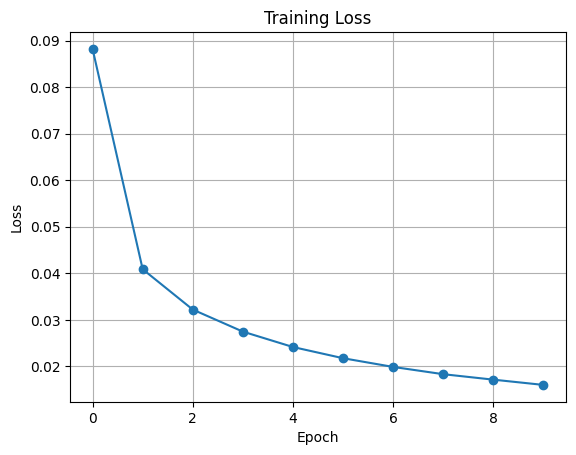

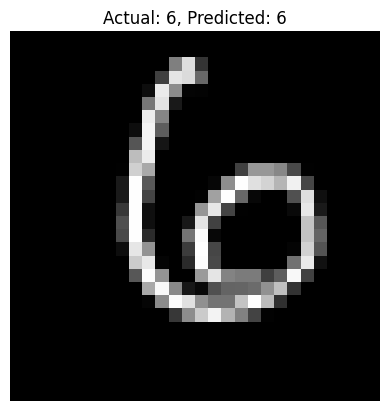

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Load and preprocess data
(X_train, y_train), (X_test, y_test) = mnist.load_data()
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

Y_train = np.eye(10)[y_train]
Y_test = np.eye(10)[y_test]

# Initialize network: input, hidden, output
np.random.seed(42)
W1 = np.random.randn(784, 64) * 0.01
b1 = np.zeros((1, 64))
W2 = np.random.randn(64, 10) * 0.01
b2 = np.zeros((1, 10))

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

# Training
epochs, lr = 10, 0.1
losses = []

for epoch in range(epochs):
    total_loss = 0

    for i in np.random.permutation(len(X_train)):
        x = X_train[i:i+1]
        y = Y_train[i:i+1]

        # Forward propagation
        a1 = sigmoid(x @ W1 + b1)
        a2 = sigmoid(a1 @ W2 + b2)

        # Binary cross-entropy loss
        loss = -np.mean(
            y * np.log(a2 + 1e-8) +
            (1 - y) * np.log(1 - a2 + 1e-8)
        )
        total_loss += loss

        # Backpropagation
        dz2 = (a2 - y) / 10
        dW2 = a1.T @ dz2
        db2 = dz2
        dz1 = (dz2 @ W2.T) * a1 * (1 - a1)
        dW1 = x.T @ dz1
        db1 = dz1

        # Update weights and biases
        W2 -= lr * dW2
        b2 -= lr * db2
        W1 -= lr * dW1
        b1 -= lr * db1

    losses.append(total_loss / len(X_train))
    print(f"Epoch {epoch+1}, Loss: {losses[-1]:.4f}")

# Evaluate test accuracy
A1 = sigmoid(X_test @ W1 + b1)
A2 = sigmoid(A1 @ W2 + b2)
predictions = np.argmax(A2, axis=1)
print("Test Accuracy:", np.mean(predictions == y_test) * 100, "%")

# Plot training loss
plt.plot(losses, marker='o')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# Display sample prediction
idx = 100
plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
plt.title(f"Actual: {y_test[idx]}, Predicted: {predictions[idx]}")
plt.axis('off')
plt.show()